# FactorVAE

Add a discriminator estimate of total correlation to encourage independent aggregate latent dimensions. This encourages factor separation; it does not guarantee human-interpretable factors.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

Using device: cuda


## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 3. FactorVAE

FactorVAE adds a total-correlation (TC) penalty to encourage statistical independence among aggregate latent dimensions. A discriminator distinguishes joint encoded vectors from vectors whose dimensions have been independently permuted. Its logit difference estimates TC up to an additive constant. This is an estimator-based training method, not a guarantee of human-interpretable factors.

In [2]:
class TCDiscriminator(nn.Module):
    def __init__(self, dim=16):
        super().__init__(); self.net = nn.Sequential(nn.Linear(dim, 128), nn.LeakyReLU(.2), nn.Linear(128, 128), nn.LeakyReLU(.2), nn.Linear(128, 2))
    def forward(self, z): return self.net(z)

def permute_dims(z):
    # Independently shuffle each dimension across the batch to approximate product marginals.
    return torch.stack([z[torch.randperm(z.size(0), device=z.device), j] for j in range(z.size(1))], dim=1)

factor_vae = MLPVAE().to(device); tc_disc = TCDiscriminator(factor_vae.latent_dim).to(device)
factor_optim = torch.optim.Adam(factor_vae.parameters(), lr=1e-3); tc_optim = torch.optim.Adam(tc_disc.parameters(), lr=1e-3)

def factorvae_train_step(x, gamma=10.0):
    x = x.to(device); mu, logvar = factor_vae.encode(x); z = factor_vae.reparameterize(mu, logvar)
    # Train TC discriminator: joint samples are class 1, dimension-shuffled samples class 0.
    joint = tc_disc(z.detach()); product = tc_disc(permute_dims(z.detach()))
    d_logits = torch.cat([joint, product]); d_labels = torch.cat([torch.ones(len(x), dtype=torch.long, device=device), torch.zeros(len(x), dtype=torch.long, device=device)])
    d_loss = F.cross_entropy(d_logits, d_labels); tc_optim.zero_grad(); d_loss.backward(); tc_optim.step()
    # Train VAE with standard ELBO plus estimated total correlation.
    recon = factor_vae.decode(z); rec, kl = vae_terms(recon, x, mu, logvar)
    tc_logits = tc_disc(z); tc_est = (tc_logits[:, 1] - tc_logits[:, 0]).mean()
    loss = rec + kl + gamma * tc_est
    factor_optim.zero_grad(); loss.backward(); factor_optim.step()
    return {'reconstruction': rec.item(), 'kl': kl.item(), 'tc_estimate': tc_est.item(), 'discriminator': d_loss.item()}

# Example: metrics = factorvae_train_step(sample_batch(train_loader))

## Full training — 50 epochs

This runs on the full MNIST training split using the model-specific objective above. In Colab, select a GPU runtime for faster training. The final checkpoint includes model weights, optimizer state, and epoch metrics.

In [3]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = factorvae_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
    print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "model": factor_vae.state_dict(),
    "extra_models": {"tc_disc": tc_disc.state_dict()},
    "optimizers": {"factor_optim": factor_optim.state_dict(),
    "tc_optim": tc_optim.state_dict()},
    "epochs": epochs,
    "history": history
}
checkpoint_path = Path("11_FactorVAE_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | reconstruction=160.1905 | kl=14.8865 | tc_estimate=0.2204 | discriminator=0.6630
Epoch 02/50 | reconstruction=112.9963 | kl=19.1207 | tc_estimate=0.2271 | discriminator=0.6404
Epoch 03/50 | reconstruction=102.4020 | kl=20.4933 | tc_estimate=0.2319 | discriminator=0.6411
Epoch 04/50 | reconstruction=98.0626 | kl=21.1779 | tc_estimate=0.2475 | discriminator=0.6347
Epoch 05/50 | reconstruction=96.1451 | kl=21.5558 | tc_estimate=0.2638 | discriminator=0.6300
Epoch 06/50 | reconstruction=94.9412 | kl=21.7664 | tc_estimate=0.2823 | discriminator=0.6252
Epoch 07/50 | reconstruction=94.1644 | kl=22.1420 | tc_estimate=0.2886 | discriminator=0.6261
Epoch 08/50 | reconstruction=93.5072 | kl=22.4126 | tc_estimate=0.3022 | discriminator=0.6209
Epoch 09/50 | reconstruction=93.0116 | kl=22.6804 | tc_estimate=0.2986 | discriminator=0.6262
Epoch 10/50 | reconstruction=92.3134 | kl=22.7759 | tc_estimate=0.3060 | discriminator=0.6217
Epoch 11/50 | reconstruction=92.0035 | kl=22.9786 | tc_es

## Inspect reconstruction and latent dependence

Use these plots alongside the objective metrics; no single number captures reconstruction quality, prior matching, latent use, and sample quality.

Discriminator-based TC estimate for this batch: -0.0672


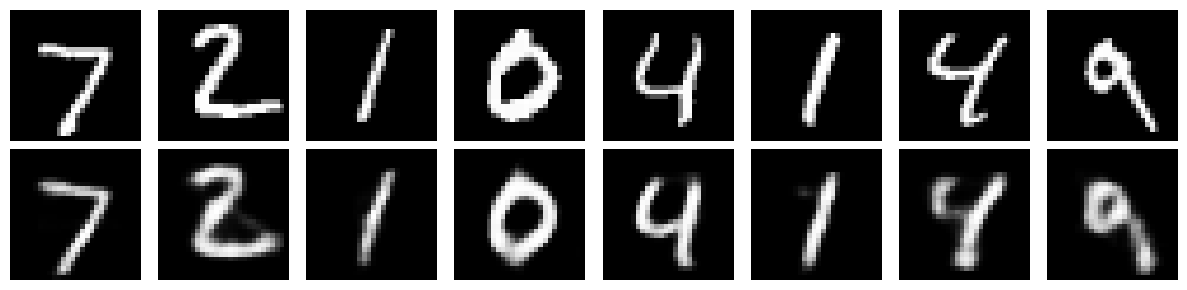

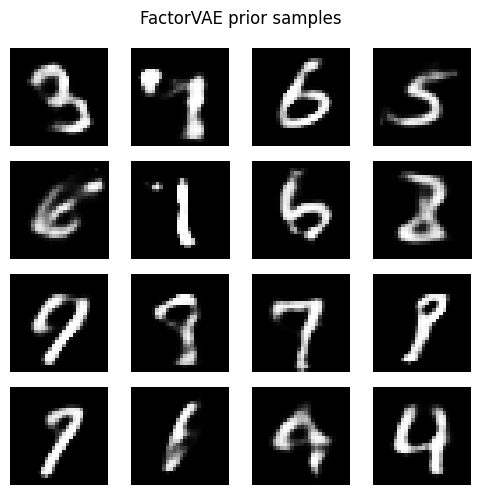

In [4]:
x = sample_batch(test_loader)[:8]
factor_vae.eval()
with torch.no_grad():
    mu, logvar = factor_vae.encode(x); recon = factor_vae.decode(factor_vae.reparameterize(mu, logvar))
    prior_samples = factor_vae.decode(torch.randn(16, factor_vae.latent_dim, device=device))
    z = factor_vae.reparameterize(mu, logvar)
    tc_logits = tc_disc(z)
    tc_estimate = (tc_logits[:, 1] - tc_logits[:, 0]).mean().item()
print(f'Discriminator-based TC estimate for this batch: {tc_estimate:.4f}')
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap='gray'); ax.axis('off')
plt.suptitle('FactorVAE prior samples'); plt.tight_layout(); plt.show()